**Step 1: Import Libraries and Load Dataset**

In [3]:

# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

# Load Dataset
df = pd.read_csv('/content/airline-passengers.csv',
                 parse_dates=['Month'],
                 index_col='Month')

# Display first 5 rows
print("First 5 Rows:")
display(df.head())

# Dataset Information
print("\nDataset Information:")
df.info()

# Dataset Shape
print("\nDataset Shape:", df.shape)

# Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())


First 5 Rows:


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB

Dataset Shape: (144, 1)

Missing Values:
Passengers    0
dtype: int64


**Step 2: Time Series Visualization (Trend Analysis)**

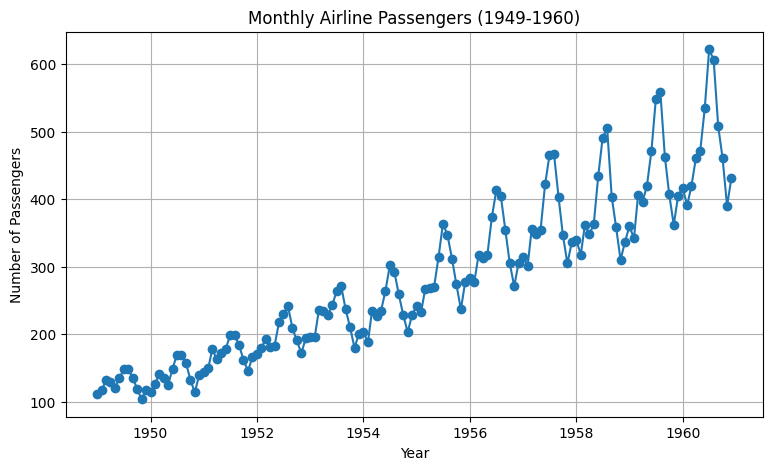

In [4]:

# Plot Time Series Data

plt.figure(figsize=(9, 5))

plt.plot(df.index, df['Passengers'], marker='o')

plt.title('Monthly Airline Passengers (1949-1960)')
plt.xlabel('Year')
plt.ylabel('Number of Passengers')

plt.grid(True)
plt.show()


**Step 3: Trend and Seasonality Decomposition**

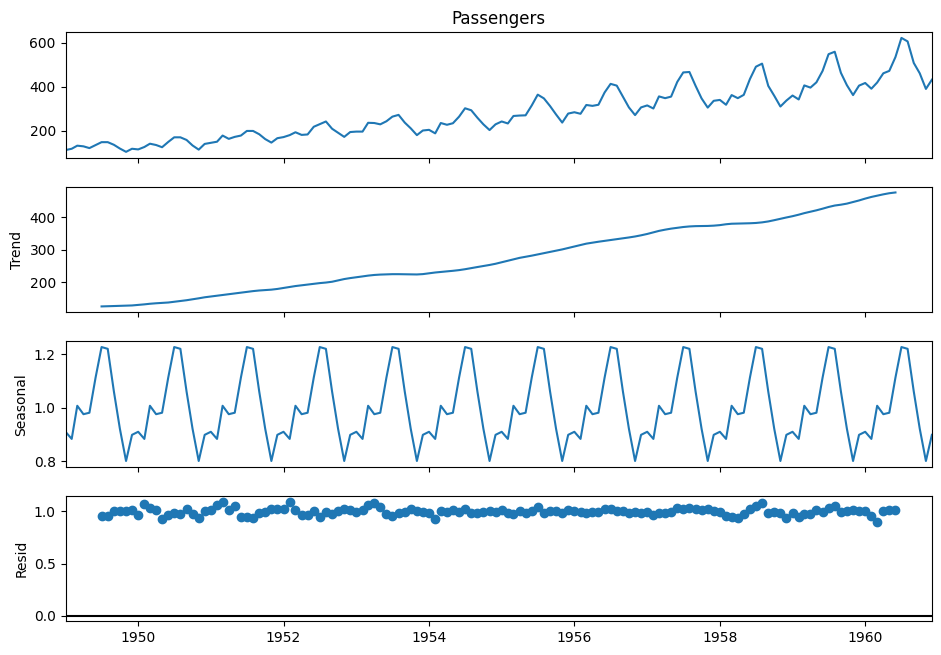

In [5]:
# Time Series Decomposition

decomposition = seasonal_decompose(
    df['Passengers'],
    model='multiplicative',
    period=12
)

fig = decomposition.plot()
fig.set_size_inches(10, 7)
plt.show()

**Step 4: Moving Averag**e

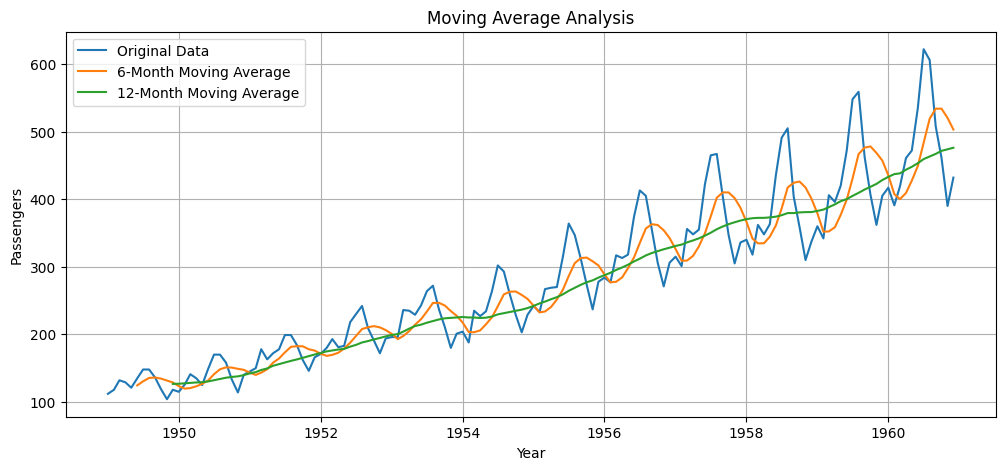

In [6]:
# Calculate Moving Averages

df['MA_6'] = df['Passengers'].rolling(window=6).mean()
df['MA_12'] = df['Passengers'].rolling(window=12).mean()

# Plot Moving Averages
plt.figure(figsize=(12, 5))

plt.plot(df.index, df['Passengers'], label='Original Data')
plt.plot(df.index, df['MA_6'], label='6-Month Moving Average')
plt.plot(df.index, df['MA_12'], label='12-Month Moving Average')

plt.title('Moving Average Analysis')
plt.xlabel('Year')
plt.ylabel('Passengers')
plt.legend()
plt.grid(True)
plt.show()

**Step 5: Train-Test Split**

In [7]:
# Train-Test Split

train = df['Passengers'][:-12]
test = df['Passengers'][-12:]

print("Training Data:", len(train), "months")
print("Testing Data:", len(test), "months")

print("\nTraining Period:", train.index.min(), "to", train.index.max())
print("Testing Period:", test.index.min(), "to", test.index.max())

Training Data: 132 months
Testing Data: 12 months

Training Period: 1949-01-01 00:00:00 to 1959-12-01 00:00:00
Testing Period: 1960-01-01 00:00:00 to 1960-12-01 00:00:00


**Step 6: ARIMA Model**

In [8]:
# Build and Train SARIMA Model

model = ARIMA(
    train,
    order=(2, 1, 1),
    seasonal_order=(1, 1, 1, 12)
)

model_fit = model.fit()

print(model_fit.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros 

                                    SARIMAX Results                                     
Dep. Variable:                       Passengers   No. Observations:                  132
Model:             ARIMA(2, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -445.700
Date:                          Thu, 12 Nov 2026   AIC                            903.399
Time:                                  15:06:26   BIC                            920.074
Sample:                              01-01-1949   HQIC                           910.171
                                   - 12-01-1959                                         
Covariance Type:                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5062      1.365     -0.371      0.711      -3.181       2.168
ar.L2         -0.0033      0.399     -0.008      0.

**Step 7: Forecasting**

In [9]:
# Forecast next 12 months

forecast = model_fit.forecast(steps=12)

print("Predicted Passenger Numbers:")
print(forecast)

Predicted Passenger Numbers:
1960-01-01    421.877485
1960-02-01    405.424550
1960-03-01    464.696999
1960-04-01    453.476362
1960-05-01    477.274412
1960-06-01    534.835426
1960-07-01    609.460547
1960-08-01    621.592159
1960-09-01    522.623641
1960-10-01    467.952979
1960-11-01    423.800744
1960-12-01    466.182533
Freq: MS, Name: predicted_mean, dtype: float64


**Step 8: Actual vs Predicted Graph + RMSE**

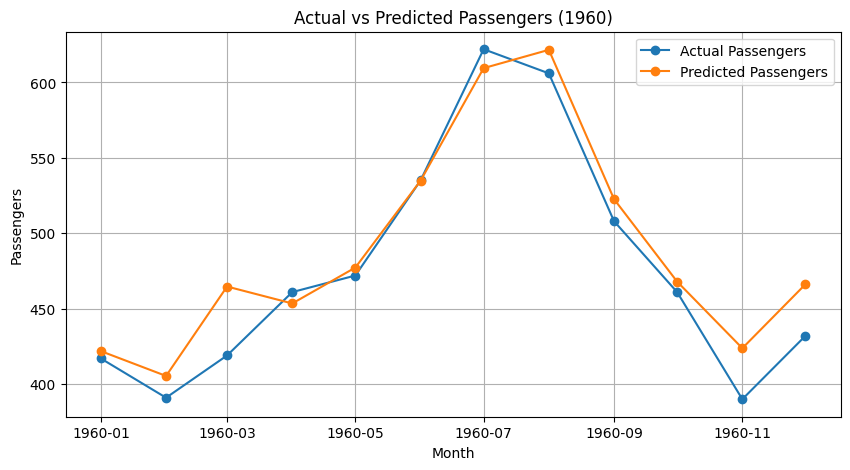

RMSE: 21.16996463074816


In [11]:
# Compare Actual vs Predicted

plt.figure(figsize=(10, 5))

plt.plot(test.index, test, marker='o', label='Actual Passengers')
plt.plot(forecast.index, forecast, marker='o', label='Predicted Passengers')

plt.title('Actual vs Predicted Passengers (1960)')
plt.xlabel('Month')
plt.ylabel('Passengers')
plt.legend()
plt.grid(True)
plt.show()

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(test, forecast))

print("RMSE:", rmse)

## Conclusion

Time Series Analysis was performed on the Air Passengers dataset (1949–1960) using Python. The dataset showed an increasing trend in passenger numbers along with yearly seasonal patterns. Multiplicative decomposition was used to identify trend, seasonality, and residual components. Moving averages of 6 and 12 months helped smooth short-term fluctuations and understand the long-term trend.

The dataset was divided into training data (1949–1959) and testing data (1960). A SARIMA model was trained to forecast passenger numbers for the 12 months of 1960. The model achieved an RMSE of approximately 21.17, indicating that the predicted values were reasonably close to the actual values. However, the model showed a convergence warning, so its performance should be interpreted with caution.

Overall, this project demonstrates how time series analysis and forecasting can help identify passenger demand patterns and support better planning and resource management in the airline industry.